# Likehood std = 0.5

### GemPy output vs. observed labels

GemPy's output $f(x; \vec{\mu})$ looks like a step function: it is (almost exactly) an integer
inside each geological unit. At each boundary, however, it rises by one along a smooth sigmoid
instead of jumping. This keeps the output differentiable with respect to the model
parameters $\vec{\mu}$, which gradient-based samplers such as NUTS need.

The observed data $g(x)$ are integer labels, i.e. a true step function. In the ideal case
(boundaries at the correct positions, all labels correct), the difference between the two is
bounded:

$$
|f(x; \vec{\mu}) - g(x)| \le 0.5 .
$$

- **Inside a unit**, the difference is essentially zero.
- **At a boundary**, it reaches 0.5, because the sigmoid crosses the half-integer exactly where
  the label jumps by one.
- The bound holds for **any sigmoid slope**; the slope only sets how wide the region with non-zero
  difference is.

The plots below show $f$, $g = \operatorname{round}(f)$ and the residual $g - f$ along a
vertical line through the model.

In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Created a custom 1D grid for Salinas_A dataset

In [ ]:
        # number of points; change as you like
x0, y0 = 20.0, 0.0        # the fixed (x, y) of the vertical line
z_top, z_bot = 0.0, -82.0

z = torch.linspace(z_top, z_bot, N, dtype=torch.float64)
custom_grid = torch.stack([torch.full_like(z, x0),
                        torch.full_like(z, y0),
                        z], dim=1)  

In [ ]:
# scale = 1.00 -> Elapsed time: 0:26:56.582650 , Elapsed time: 0:23:07.628800
# scale = 5.00 -> Elapsed time: 0:43:59.924104 , Elapsed time: 0:37:47.318528
# scale = 10.0 -> Elapsed time: 0:39:20.479837 , Elapsed time: 0:35:59.768216
# scale = 15.0 -> Elapsed time: 0:41:25.558003 , Elapsed time: 0:37:31.748686
# scale = 20.0 -> Elapsed time: 0:54:29.781214 , Elapsed time: 0:49:42.646551
# scale = 25.0 -> Elapsed time: 1:03:57.452889 , Elapsed time: 0:58:50.012719
# scale = 30.0 -> Elapsed time: 2:47:32.724667 , Elapsed time: 2:37:05.658349
# scale = 35.0 -> Elapsed time: 2:40:33.986997 
# scale = 40.0 -> Elapsed time: 1:45:31.823500
# scale = 45.0 -> Elapsed time: 1:14:27.513500 
# scale = 50.0 -> Elapsed time: 3:05:12.896291

# Output generated by Salinas a dataset for the custom grid defined in the above cell

In [10]:
output= torch.tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0001, 1.0001, 1.0002, 1.0002, 1.0004, 1.0005, 1.0008, 1.0012, 1.0019,
        1.0029, 1.0043, 1.0066, 1.0100, 1.0151, 1.0228, 1.0344, 1.0516, 1.0767,
        1.1128, 1.1629, 1.2296, 1.3137, 1.4123, 1.5187, 1.6236, 1.7184, 1.7971,
        1.8583, 1.9034, 1.9353, 1.9572, 1.9719, 1.9817, 1.9881, 1.9923, 1.9950,
        1.9968, 1.9979, 1.9987, 1.9992, 1.9995, 1.9997, 1.9998, 1.9999, 1.9999,
        1.9999, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
        2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0001,
        2.0001, 2.0002, 2.0004, 2.0006, 2.0010, 2.0018, 2.0030, 2.0050, 2.0084,
        2.0141, 2.0235, 2.0391, 2.0642, 2.1037, 2.1634, 2.2479, 2.3573, 2.4840,
        2.6127, 2.7273, 2.8181, 2.8835, 2.9275, 2.9557, 2.9732, 2.9839, 2.9904,
        2.9943, 2.9966, 2.9980, 2.9988, 2.9993, 2.9996, 2.9997, 2.9999, 2.9999,
        2.9999, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
        3.0000, 3.0001, 3.0001, 3.0002, 3.0003, 3.0005, 3.0007, 3.0012, 3.0020,
        3.0032, 3.0051, 3.0083, 3.0133, 3.0214, 3.0341, 3.0540, 3.0846, 3.1299,
        3.1944, 3.2805, 3.3864, 3.5042, 3.6215, 3.7260, 3.8105, 3.8734, 3.9175,
        3.9472, 3.9666, 3.9790, 3.9869, 3.9918, 3.9949, 3.9968, 3.9980, 3.9988,
        3.9992, 3.9995, 3.9997, 3.9998, 3.9999, 3.9999, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000, 4.0000,
        4.0000, 4.0000, 4.0000, 4.0001, 4.0001, 4.0001, 4.0002, 4.0004, 4.0006,
        4.0010, 4.0016, 4.0027, 4.0044, 4.0071, 4.0114, 4.0185, 4.0298, 4.0476,
        4.0753, 4.1172, 4.1779, 4.2608, 4.3652, 4.4841, 4.6049, 4.7142, 4.8031,
        4.8695, 4.9158, 4.9467, 4.9667, 4.9794, 4.9873, 4.9922, 4.9952, 4.9971,
        4.9982, 4.9989, 4.9993, 4.9996, 4.9997, 4.9998, 4.9999, 4.9999, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0001, 5.0001, 5.0002, 5.0003, 5.0005, 5.0009, 5.0015, 5.0024,
        5.0041, 5.0069, 5.0115, 5.0193, 5.0320, 5.0528, 5.0858, 5.1365, 5.2102,
        5.3096, 5.4304, 5.5602, 5.6822, 5.7835, 5.8592, 5.9114, 5.9455, 5.9669,
        5.9801, 5.9881, 5.9929, 5.9958, 5.9975, 5.9985, 5.9991, 5.9995, 5.9997,
        5.9998, 5.9999, 5.9999, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000, 6.0000,
        6.0000]).numpy()

In [11]:
# In Idea case, the observed data should be the rounded value of the output,
# but in real case, there will be some of the segments are wrongly classified 
# and the boundaries of the segments are not exactly at the right position. 


In [12]:
obs = np.round(output)  # observed data, rounded value of the output

In [13]:
res = obs - output # residual between the output and the observed data

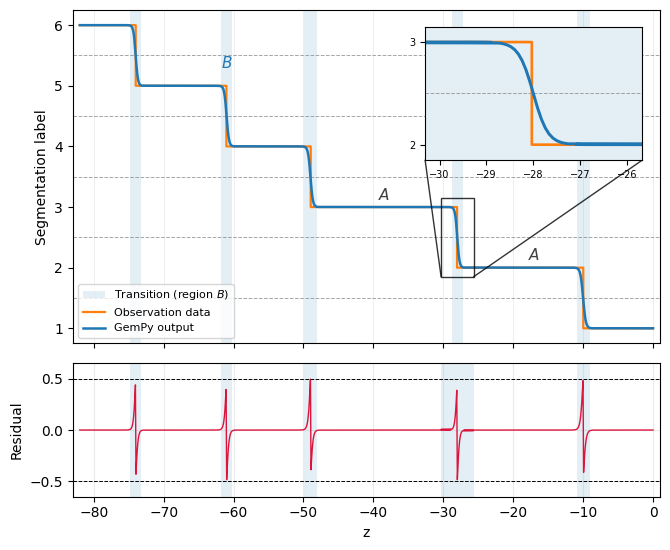

In [14]:

import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

tol, which, pad = 0.005, 1, 1.5
in_ramp = np.abs(output - np.round(output)) > tol
edges = np.flatnonzero(np.diff(np.r_[0, in_ramp.astype(int), 0]))
strips = list(zip(edges[::2], edges[1::2] - 1))
lo, hi = int(round(output.min())), int(round(output.max()))
 
def draw(ax, lw_scale=1.0, legend=False):
    for k, (i0, i1) in enumerate(strips):
        ax.axvspan(z[i0], z[i1], color='tab:blue', alpha=0.12, lw=0,
                   label='Transition (region $B$)' if k == 0 else None)
    ax.plot(z, obs, color='tab:orange', lw=1.6 * lw_scale, drawstyle='steps-mid', label='Observation data')
    ax.plot(z, output, color='tab:blue', lw=1.8 * lw_scale, label='GemPy output')
    ax.set_yticks(np.arange(lo + 0.5, hi, 1), minor=True)
    ax.grid(which='minor', axis='y', ls='--', lw=0.7, color='gray', alpha=0.7)
    ax.tick_params(axis='y', which='minor', length=0)
 
fig, (ax, axr) = plt.subplots(2, 1, figsize=(6.8, 5.6), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1.2]})
draw(ax)
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.grid(which='major', axis='x', lw=0.5, alpha=0.3)
ax.set_ylabel('Segmentation label')
ax.legend(loc='lower left', fontsize=8)
 
# region labels on the main plot
ax.text(-38.5, 3.12, '$A$', fontsize=11, ha='center', color='0.25')
ax.text(-17.0, 2.12, '$A$', fontsize=11, ha='center', color='0.25')
i0, i1 = strips[3]
ax.text((z[i0] + z[i1]) / 2, 5.3, '$B$', fontsize=11, ha='center', color='tab:blue')
 
# zoom on one transition
i0, i1 = strips[which]
x1, x2 = sorted([z[i0], z[i1]]); x1 -= pad; x2 += pad
level = np.round(output[(i0 + i1) // 2] - 0.5)
axins = ax.inset_axes([0.60, 0.55, 0.37, 0.40])
draw(axins, lw_scale=1.2)
axins.set_xlim(x1, x2); axins.set_ylim(level - 0.15, level + 1.15)
axins.set_yticks([level, level + 1])
axins.tick_params(labelsize=7)
axins.xaxis.set_major_locator(plt.MaxNLocator(5))
ax.indicate_inset_zoom(axins, edgecolor='black', alpha=0.8)
 
# residual panel
for (i0, i1) in strips:
    axr.axvspan(z[i0], z[i1], color='tab:blue', alpha=0.12, lw=0)
axr.plot(z, res, color='crimson', lw=1.0)
axr.axhline(0.5, color='k', ls='--', lw=0.7); axr.axhline(-0.5, color='k', ls='--', lw=0.7)
axr.set_ylim(-0.65, 0.65); axr.set_yticks([-0.5, 0, 0.5])
axr.set_ylabel('Residual')
axr.set_xlabel('z')
axr.set_xlim(-83, 1)
axr.grid(alpha=0.25)
 
fig.tight_layout()